In [18]:
import numpy as np

In [19]:
X = np.array([
    [-2, -2],
    [-1.5, -2],
    [-2, -1.5],

    [2, 2],
    [1.5, 2],
    [2, 1.5],

    [-2, 2],
    [-1.5, 2],
    [-2, 1.5]
])

y = np.array([
    0, 0, 0,
    1, 1, 1,
    2, 2, 2
])
print("X shape:", X.shape)
print("y shape:", y.shape)


X shape: (9, 2)
y shape: (9,)


In [20]:
y = np.array([0, 0, 0, 1, 1, 1, 2, 2, 2])
H = np.eye(3)[y]
print(H)

[[1. 0. 0.]
 [1. 0. 0.]
 [1. 0. 0.]
 [0. 1. 0.]
 [0. 1. 0.]
 [0. 1. 0.]
 [0. 0. 1.]
 [0. 0. 1.]
 [0. 0. 1.]]


In [21]:

W1 = np.array([
    [0.05,-0.08,0.03],
    [-0.04, 0.06, 0.09]
])
W2 = np.array([
    [0.07,-0.02,0.04],
    [-0.06,0.08,-0.03],
    [0.02,0.05,-0.07]
])
b1 = np.zeros(3)
b2 = np.zeros(3)
Z1 = X@W1+b1
A1 = np.maximum(Z1, 0)
Z2 = A1@W2+b2
print(A1)
print(Z2)


[[0.    0.04  0.   ]
 [0.005 0.    0.   ]
 [0.    0.07  0.   ]
 [0.02  0.    0.24 ]
 [0.    0.    0.225]
 [0.04  0.    0.195]
 [0.    0.28  0.12 ]
 [0.    0.24  0.135]
 [0.    0.25  0.075]]
[[-2.400e-03  3.200e-03 -1.200e-03]
 [ 3.500e-04 -1.000e-04  2.000e-04]
 [-4.200e-03  5.600e-03 -2.100e-03]
 [ 6.200e-03  1.160e-02 -1.600e-02]
 [ 4.500e-03  1.125e-02 -1.575e-02]
 [ 6.700e-03  8.950e-03 -1.205e-02]
 [-1.440e-02  2.840e-02 -1.680e-02]
 [-1.170e-02  2.595e-02 -1.665e-02]
 [-1.350e-02  2.375e-02 -1.275e-02]]


In [22]:
def softmax(ap):
    b = ap - np.max(ap, axis = 1, keepdims = True)
    ex = np.exp(b)
    return ex / np.sum(ex, axis = 1, keepdims = True)
A2 = softmax(Z2)
print(A2)


[[0.33257767 0.33444533 0.332977  ]
 [0.3334     0.33325    0.33334999]
 [0.33201078 0.33528048 0.33270874]
 [0.33518139 0.33699626 0.32782235]
 [0.33481472 0.33708237 0.32810291]
 [0.3351569  0.33591185 0.32893125]
 [0.3288033  0.34318158 0.32801512]
 [0.32965983 0.34230813 0.32803204]
 [0.3290878  0.3415775  0.32933471]]


In [23]:
def cross_entropy(a,ap):
    ep = 1e-15
    ap = np.clip(ap,ep,1-ep)
    return -np.sum(a * np.log(ap))
print("loss:", cross_entropy(H,A2))

loss: 9.90792017065781


In [24]:

def backprop():
    global W1, b1, W2, b2
    lr = 0.01
    for i in range(1000):
    
        
        Z1 = X @ W1 + b1
        A1 = np.maximum(Z1, 0)
    
        Z2 = A1 @ W2 + b2
        A2 = softmax(Z2)
    
        
        loss = cross_entropy(H, A2)
    
        if i % 10 == 0:
            print(i, loss)
    
        
        dZ2 = A2 - H
        dW2 = A1.T @ dZ2
        db2 = np.sum(dZ2, axis=0)
    
        dA1 = dZ2 @ W2.T
        dZ1 = dA1 * (Z1 > 0)
    
        dW1 = X.T @ dZ1
        db1 = np.sum(dZ1, axis=0)
    
        
        W1 -= lr * dW1
        b1 -= lr * db1
        W2 -= lr * dW2
        b2 -= lr * db2
   
backprop()


    

0 9.90792017065781
10 9.748353109967955
20 9.402531833623666
30 8.486089811631306
40 6.733272273508551
50 4.447515218684759
60 2.3840158370861477
70 1.2709692369646912
80 0.7691024581942525
90 0.521187180869013
100 0.38244941893252976
110 0.2965896879909171
120 0.23936311193605112
130 0.19900459837505097
140 0.16927529182063933
150 0.14660943254762873
160 0.128837575318083
170 0.11459146116225631
180 0.10294431383004145
190 0.0932736316308697
200 0.08512734232518943
210 0.07818510291806076
220 0.07220843668875379
230 0.06701260882282882
240 0.062460065868291274
250 0.0584420414864404
260 0.054873408736721085
270 0.05168350180432762
280 0.048817645227689443
290 0.046230348009047684
300 0.04388410516918423
310 0.04174773909196888
320 0.03979513437333598
330 0.0380042651473359
340 0.036356592781771384
350 0.03483590996933949
360 0.033428482963827034
370 0.032122492358691086
380 0.030907714100861024
390 0.029775189406087525
400 0.02871704258743069
410 0.027726383805713545
420 0.02679715119

In [25]:
Z1 = X @ W1 + b1
A1 = np.maximum(Z1, 0)

Z2 = A1 @ W2 + b2
A2 = softmax(Z2)

In [26]:
predictions = np.argmax(A2, axis=1)

print(predictions)
print(y)
print(A2)

[0 0 0 1 1 1 2 2 2]
[0 0 0 1 1 1 2 2 2]
[[9.99654275e-01 1.63689363e-04 1.82035851e-04]
 [9.99268111e-01 3.40882227e-04 3.91006474e-04]
 [9.98279760e-01 5.54894621e-04 1.16534579e-03]
 [1.02554548e-04 9.99752111e-01 1.45333973e-04]
 [3.31073842e-04 9.98243990e-01 1.42493621e-03]
 [2.88288731e-04 9.99572404e-01 1.39306848e-04]
 [1.20843748e-04 3.77739155e-04 9.99501417e-01]
 [2.95741104e-04 7.80674723e-04 9.98923584e-01]
 [7.01373433e-04 1.02539214e-03 9.98273234e-01]]


In [27]:
X_new = np.array([
    [-1.7, -1.8],   
    [-2.3, -2.1],   

    [1.8, 1.7],     
    [2.3, 2.1],     

    [-1.8, 1.7],    
    [-2.2, 2.3]    
])
Z1_new = X_new @ W1 + b1
A1_new = np.maximum(Z1_new, 0)

Z2_new = A1_new @ W2 + b2
A2_new = softmax(Z2_new)

prediction = np.argmax(A2_new, axis=1)

print(A2_new)
print(prediction)


[[9.99155308e-01 3.92177721e-04 4.52514067e-04]
 [9.99823379e-01 8.48454905e-05 9.17753294e-05]
 [3.04787711e-04 9.99342003e-01 3.53209644e-04]
 [4.12537097e-05 9.99921520e-01 3.72266288e-05]
 [3.56047607e-04 9.07229185e-04 9.98736723e-01]
 [4.09957097e-05 1.57204546e-04 9.99801800e-01]]
[0 0 1 1 2 2]


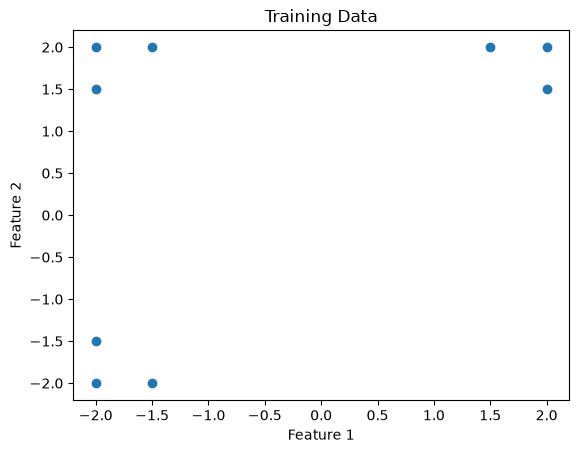

In [28]:
import matplotlib.pyplot as plt

plt.scatter(X[:, 0], X[:, 1])

plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.title("Training Data")

plt.show()

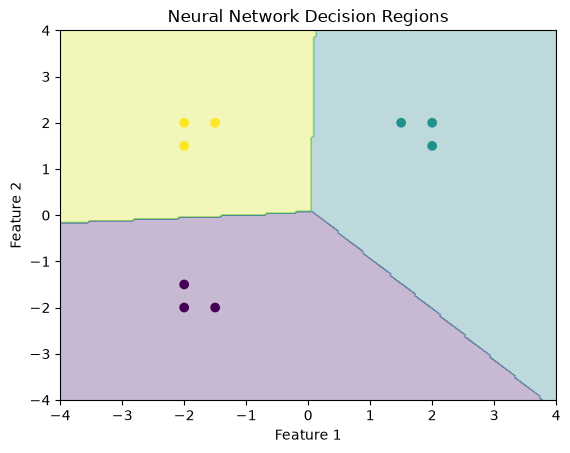

In [ ]:
import numpy as np
import matplotlib.pyplot as plt


x1 = np.linspace(-4, 4, 200)
x2 = np.linspace(-4, 4, 200)

xx, yy = np.meshgrid(x1, x2)

grid = np.c_[xx.ravel(), yy.ravel()]


Z1_grid = grid @ W1 + b1
A1_grid = np.maximum(Z1_grid, 0)

Z2_grid = A1_grid @ W2 + b2
A2_grid = softmax(Z2_grid)

pred_grid = np.argmax(A2_grid, axis=1)


pred_grid = pred_grid.reshape(xx.shape)


plt.contourf(xx, yy, pred_grid, alpha=0.3)


plt.scatter(X[:, 0], X[:, 1], c=y)

plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.title("Neural Network Decision Regions")

plt.show()

In [30]:
X_test = np.array([
    [0, 0],
    [-0.5, -0.5],
    [0.5, 0.5],
    [-0.5, 0.5],
    [0.5, -0.5],

    [-1, 0],
    [0, -1],
    [1, 0],
    [0, 1],

    [-1, 1],
    [1, 1],
    [-1, -1],
    [1, -1]
])
Z1_new = X_test @ W1 + b1
A1_new = np.maximum(Z1_new, 0)

Z2_new = A1_new @ W2 + b2
A2_new = softmax(Z2_new)

prediction = np.argmax(A2_new, axis=1)

print(A2_new)
print(prediction)

[[0.4382353  0.26732113 0.29444357]
 [0.88807474 0.03707953 0.07484573]
 [0.06430065 0.83449474 0.10120461]
 [0.09635407 0.07258388 0.83106205]
 [0.54462919 0.34653795 0.10883285]
 [0.48057481 0.04238368 0.47704151]
 [0.93964377 0.02536775 0.03498848]
 [0.05095167 0.92382736 0.02522097]
 [0.03801613 0.42904354 0.53294033]
 [0.00923673 0.01124476 0.97951851]
 [0.00829921 0.97908743 0.01261336]
 [0.98456122 0.00629052 0.00914826]
 [0.52809932 0.40472056 0.06718012]]
[0 0 1 2 0 0 0 1 2 2 1 0 0]


In [31]:
X_test = np.array([
    [-10, -10],
    [10, 10],
    [-10, 10],
    [10, -10],

    [-20, 0],
    [20, 0],
    [0, -20],
    [0, 20]
])
Z1_new = X_test @ W1 + b1
A1_new = np.maximum(Z1_new, 0)

Z2_new = A1_new @ W2 + b2
A2_new = softmax(Z2_new)

prediction = np.argmax(A2_new, axis=1)

print(A2_new)
print(prediction)

[[1.00000000e+00 3.77583248e-17 1.23079667e-17]
 [4.71889714e-20 1.00000000e+00 3.82118499e-20]
 [3.05551600e-19 5.48272117e-16 1.00000000e+00]
 [4.38403612e-02 9.56157994e-01 1.64433012e-06]
 [6.99022761e-03 2.95564783e-13 9.93009772e-01]
 [3.82391106e-24 1.00000000e+00 5.28158677e-28]
 [1.00000000e+00 3.39338628e-20 8.22864024e-21]
 [1.07617423e-19 1.39491251e-01 8.60508749e-01]]
[0 1 2 1 2 1 0 2]


In [32]:
X_test = np.random.uniform(-4, 4, size=(100, 2))
Z1_new = X_test @ W1 + b1
A1_new = np.maximum(Z1_new, 0)

Z2_new = A1_new @ W2 + b2
A2_new = softmax(Z2_new)

prediction = np.argmax(A2_new, axis=1)

print(A2_new)
print(prediction)

[[3.21409576e-01 4.44932287e-02 6.34097195e-01]
 [9.64318958e-01 2.35402318e-02 1.21408101e-02]
 [8.99827091e-03 3.74571970e-04 9.90627157e-01]
 [6.72564653e-08 8.66664567e-07 9.99999066e-01]
 [9.99674255e-01 1.54429123e-04 1.71316294e-04]
 [8.34865873e-03 9.90789425e-01 8.61916331e-04]
 [9.32510680e-01 2.82850495e-02 3.92042700e-02]
 [1.31740812e-03 9.98324253e-01 3.58338699e-04]
 [9.99958924e-01 2.03502505e-05 2.07259254e-05]
 [9.99326349e-01 3.14331248e-04 3.59319541e-04]
 [9.64312298e-01 9.07107804e-03 2.66166238e-02]
 [3.90503442e-05 9.99929428e-01 3.15214637e-05]
 [7.74997824e-04 9.99031420e-01 1.93581940e-04]
 [1.46856038e-04 2.83500344e-04 9.99569644e-01]
 [9.99782731e-01 1.03908756e-04 1.13360668e-04]
 [2.43321820e-04 9.76428493e-01 2.33281853e-02]
 [3.25384019e-06 9.99996408e-01 3.37780276e-07]
 [2.67107690e-03 9.55994578e-01 4.13343452e-02]
 [1.30944032e-05 9.99985206e-01 1.69948629e-06]
 [9.99993494e-01 3.34681708e-06 3.15873732e-06]
 [5.88604083e-04 1.88839243e-02 9.805274

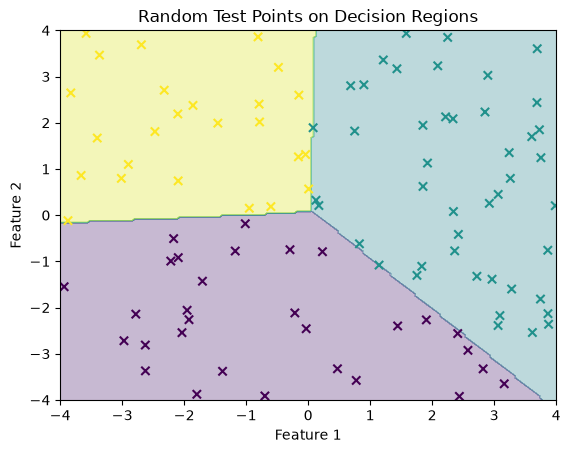

In [ ]:


Z1_test = X_test @ W1 + b1
A1_test = np.maximum(Z1_test, 0)

Z2_test = A1_test @ W2 + b2
A2_test = softmax(Z2_test)

predictions_test = np.argmax(A2_test, axis=1)


plt.contourf(xx, yy, pred_grid, alpha=0.3)


plt.scatter(
    X_test[:, 0],
    X_test[:, 1],
    c=predictions_test,
    marker="x"
)

plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.title("Random Test Points on Decision Regions")

plt.show()

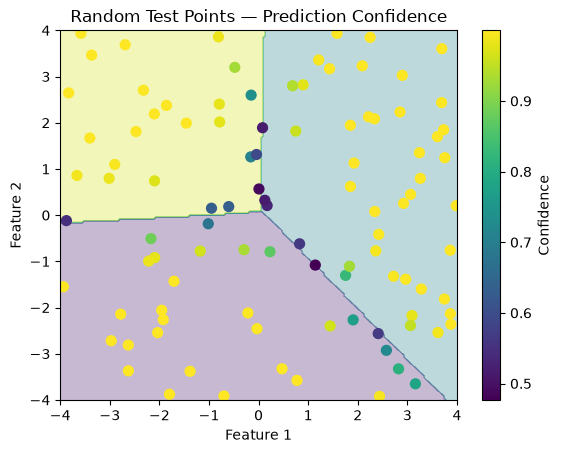

In [34]:
confidence = np.max(A2_test, axis=1)
import matplotlib.pyplot as plt

confidence = np.max(A2_test, axis=1)

plt.contourf(xx, yy, pred_grid, alpha=0.3)

plt.scatter(
    X_test[:, 0],
    X_test[:, 1],
    c=confidence,
    s=50,
    cmap="viridis"
)

plt.colorbar(label="Confidence")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.title("Random Test Points — Prediction Confidence")

plt.show()

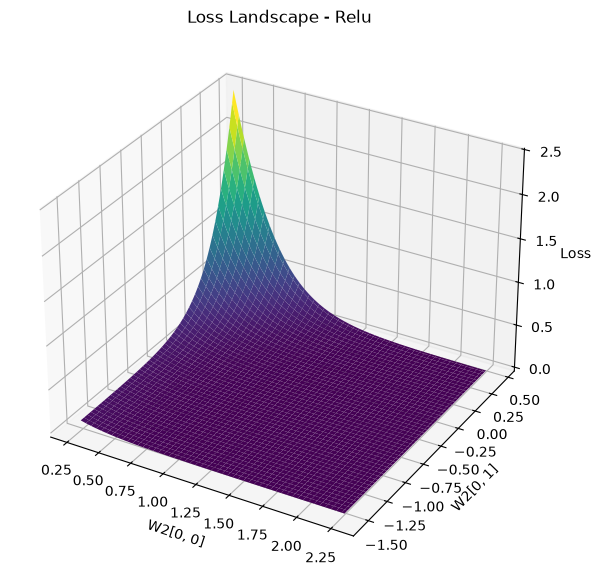

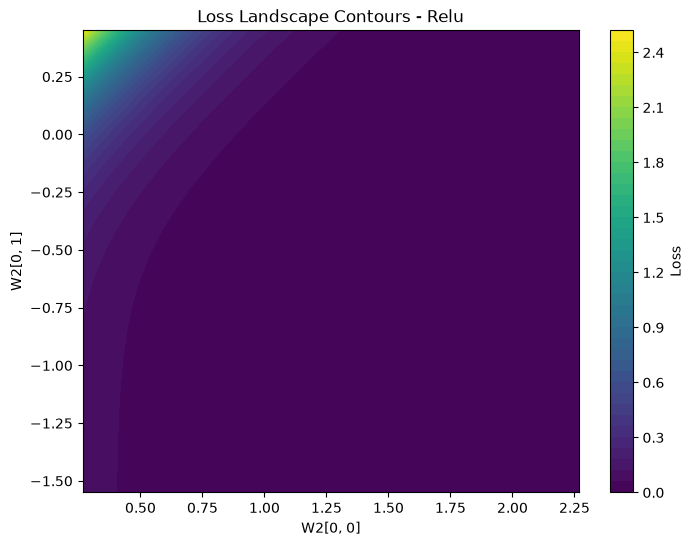

In [35]:

import numpy as np
import matplotlib.pyplot as plt


activation = "relu"  


W2_trained = W2.copy()


w_a = np.linspace(W2_trained[0, 0] - 1,
                  W2_trained[0, 0] + 1, 100)
w_b = np.linspace(W2_trained[0, 1] - 1,
                  W2_trained[0, 1] + 1, 100)

WA, WB = np.meshgrid(w_a, w_b)
loss_grid = np.zeros_like(WA)

def calculate_loss(w_a, w_b):
    W2_temp = W2_trained.copy()
    W2_temp[0, 0] = w_a
    W2_temp[0, 1] = w_b

    Z1 = X @ W1 + b1

    if activation == "relu":
        A1 = np.maximum(Z1, 0)
    else:
        A1 = 1 / (1 + np.exp(-Z1))

    Z2 = A1 @ W2_temp + b2

    
    Z2 = Z2 - np.max(Z2, axis=1, keepdims=True)
    exp_Z2 = np.exp(Z2)
    A2 = exp_Z2 / np.sum(exp_Z2, axis=1, keepdims=True)

    return -np.sum(H * np.log(np.clip(A2, 1e-15, 1.0)))

for i in range(WA.shape[0]):
    for j in range(WA.shape[1]):
        loss_grid[i, j] = calculate_loss(WA[i, j], WB[i, j])


fig = plt.figure(figsize=(10, 7))
ax = fig.add_subplot(111, projection="3d")

ax.plot_surface(WA, WB, loss_grid, cmap="viridis")

ax.set_xlabel("W2[0, 0]")
ax.set_ylabel("W2[0, 1]")
ax.set_zlabel("Loss")
ax.set_title(f"Loss Landscape - {activation.capitalize()}")

plt.show()


plt.figure(figsize=(8, 6))
plt.contourf(WA, WB, loss_grid, levels=40, cmap="viridis")
plt.colorbar(label="Loss")
plt.xlabel("W2[0, 0]")
plt.ylabel("W2[0, 1]")
plt.title(f"Loss Landscape Contours - {activation.capitalize()}")
plt.show()
